<>:10: SyntaxWarning: invalid escape sequence '\s'
<>:10: SyntaxWarning: invalid escape sequence '\s'
C:\Users\ASUS\AppData\Local\Temp\ipykernel_19436\1353686664.py:10: SyntaxWarning: invalid escape sequence '\s'
  df = pd.read_csv("results\seed_sweep.csv")


Hole ratio: 0.4

Số seed theo kích cỡ và phương pháp:
method  sat_commander  sat_product  sat_pysat_bitwise  sat_pysat_pairwise  \
N                                                                           
25                  3            3                  3                   3   
36                  3            3                  3                   3   
49                  3            3                  3                   3   
64                  3            3                  3                   3   
81                  3            3                  3                   3   

method  sat_pysat_seqcounter  
N                             
25                         3  
36                         3  
49                         3  
64                         3  
81                         3  

Bảng trung bình số biến:
method  sat_commander  sat_product  sat_pysat_bitwise  sat_pysat_pairwise  \
N                                                                           
25       

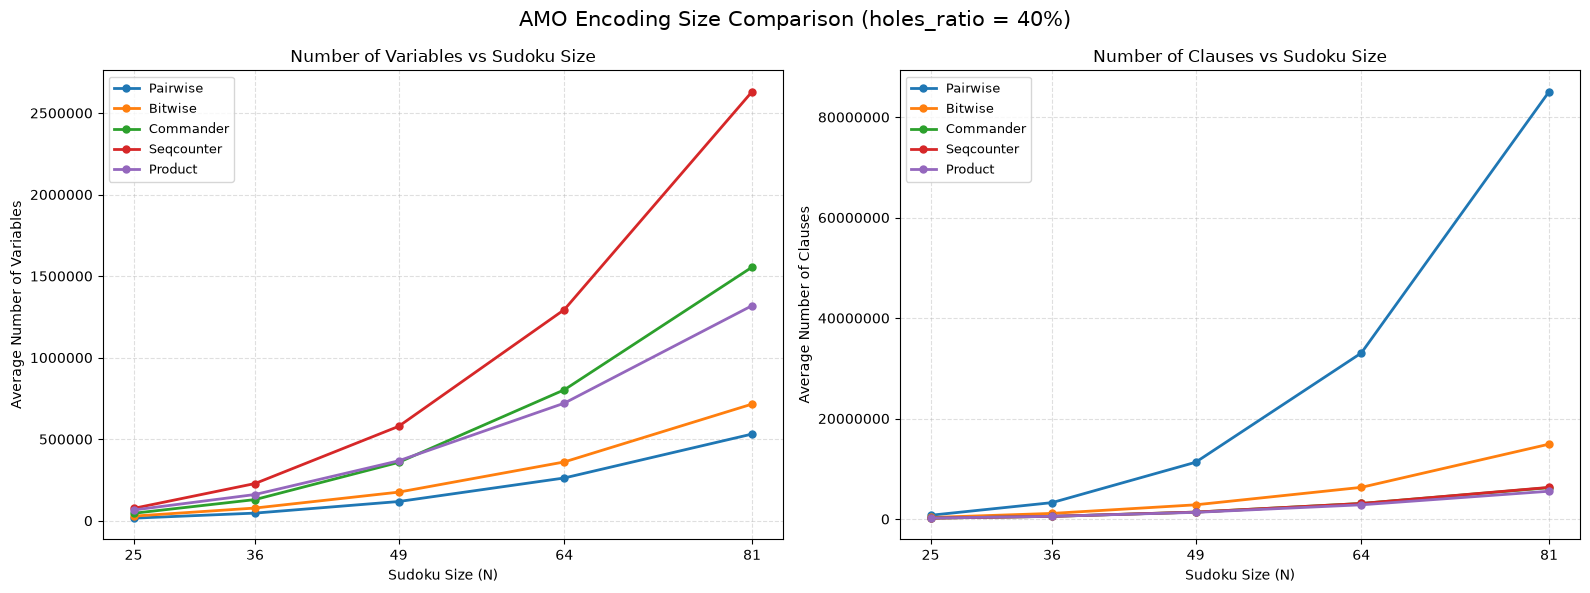

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path

OUTPUT_DIR = Path(r"C:\kì I 2026-2027\Các vấn đề hiện đại của KHMT\sudoku-sat-encodings\benchmarks\results")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

df = pd.read_csv("results\seed_sweep.csv")

sizes = [25, 36, 49, 64, 81]
HOLES_RATIO = 0.40

methods = [
    "sat_pysat_pairwise",
    "sat_pysat_bitwise",
    "sat_commander",
    "sat_pysat_seqcounter",
    "sat_product"
]

method_names = {
    "sat_pysat_pairwise": "Pairwise",
    "sat_pysat_bitwise": "Bitwise",
    "sat_commander": "Commander",
    "sat_pysat_seqcounter": "Seqcounter",
    "sat_product": "Product"
}

data = df[
    df["N"].isin(sizes)
    & df["method"].isin(methods)
    & np.isclose(df["holes_ratio"], HOLES_RATIO)
].copy()

for col in ["N", "seed", "n_vars", "n_clauses"]:
    data[col] = pd.to_numeric(data[col], errors="coerce")

data = data.dropna(
    subset=["N", "seed", "n_vars", "n_clauses"]
)

data = data.drop_duplicates(
    subset=["N", "method", "seed"]
)

summary = (
    data.groupby(["N", "method"], as_index=False)
    .agg(
        mean_vars=("n_vars", "mean"),
        mean_clauses=("n_clauses", "mean"),
        seed_count=("seed", "nunique")
    )
)

summary = summary[summary["seed_count"] == 3].copy()

print("Hole ratio:", HOLES_RATIO)
print("\nSố seed theo kích cỡ và phương pháp:")
print(
    summary.pivot(
        index="N",
        columns="method",
        values="seed_count"
    ).reindex(sizes)
)

print("\nBảng trung bình số biến:")
print(
    summary.pivot(
        index="N",
        columns="method",
        values="mean_vars"
    ).reindex(sizes).round(2)
)

print("\nBảng trung bình số mệnh đề:")
print(
    summary.pivot(
        index="N",
        columns="method",
        values="mean_clauses"
    ).reindex(sizes).round(2)
)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

metrics = [
    ("mean_vars", "Number of Variables",
     "amo_number_of_variables.png"),
    ("mean_clauses", "Number of Clauses",
     "amo_number_of_clauses.png")
]

for ax, (metric, ylabel, filename) in zip(axes, metrics):
    for method in methods:
        d = summary[summary["method"] == method].sort_values("N")

        if not d.empty:
            ax.plot(
                d["N"],
                d[metric],
                marker="o",
                linewidth=2,
                markersize=5,
                label=method_names[method]
            )

    ax.set_title(f"{ylabel} vs Sudoku Size")
    ax.set_xlabel("Sudoku Size (N)")
    ax.set_ylabel(f"Average {ylabel}")
    ax.set_xticks(sizes)
    ax.ticklabel_format(axis="y", style="plain", useOffset=False)
    ax.grid(True, linestyle="--", alpha=0.4)
    ax.legend(fontsize=9)

    fig_single, ax_single = plt.subplots(figsize=(9, 6))

    for method in methods:
        d = summary[summary["method"] == method].sort_values("N")

        if not d.empty:
            ax_single.plot(
                d["N"],
                d[metric],
                marker="o",
                linewidth=2,
                markersize=5,
                label=method_names[method]
            )

    ax_single.set_title(f"{ylabel} vs Sudoku Size "
                        f"(holes_ratio = {HOLES_RATIO:.0%})")
    ax_single.set_xlabel("Sudoku Size (N)")
    ax_single.set_ylabel(f"Average {ylabel}")
    ax_single.set_xticks(sizes)
    ax_single.ticklabel_format(axis="y", style="plain", useOffset=False)
    ax_single.grid(True, linestyle="--", alpha=0.4)
    ax_single.legend(title="AMO Encoding")
    fig_single.tight_layout()
    fig_single.savefig(OUTPUT_DIR / filename, dpi=300, bbox_inches="tight")
    plt.close(fig_single)

fig.suptitle(
    f"AMO Encoding Size Comparison "
    f"(holes_ratio = {HOLES_RATIO:.0%})",
    fontsize=15
)
fig.tight_layout()
plt.show()

<>:10: SyntaxWarning: invalid escape sequence '\s'
<>:10: SyntaxWarning: invalid escape sequence '\s'
C:\Users\ASUS\AppData\Local\Temp\ipykernel_19436\2093573994.py:10: SyntaxWarning: invalid escape sequence '\s'
  df = pd.read_csv("results\seed_sweep.csv")


N=64, method=sat_pysat_bitwise, seed=3: dùng encode_time của seed=2 (2.802500s)
N=64, method=sat_commander, seed=3: dùng encode_time của seed=2 (1.642400s)
N=64, method=sat_product, seed=3: dùng encode_time của seed=2 (1.878000s)
N=64, method=sat_pysat_pairwise, seed=3: dùng encode_time của seed=2 (14.087800s)
N=64, method=sat_pysat_seqcounter, seed=3: dùng encode_time của seed=2 (1.082700s)
N=81, method=sat_commander, seed=3: dùng encode_time của seed=2 (4.088300s)
N=81, method=sat_product, seed=3: dùng encode_time của seed=2 (3.425400s)
N=81, method=sat_pysat_bitwise, seed=3: dùng encode_time của seed=2 (7.198300s)
N=81, method=sat_pysat_pairwise, seed=3: dùng encode_time của seed=2 (52.864700s)
N=81, method=sat_pysat_seqcounter, seed=3: dùng encode_time của seed=2 (2.577300s)
Số cấu hình hợp lệ: 25

Bảng thời gian mã hóa trung bình:
method  sat_commander  sat_product  sat_pysat_bitwise  sat_pysat_pairwise  \
N                                                                          

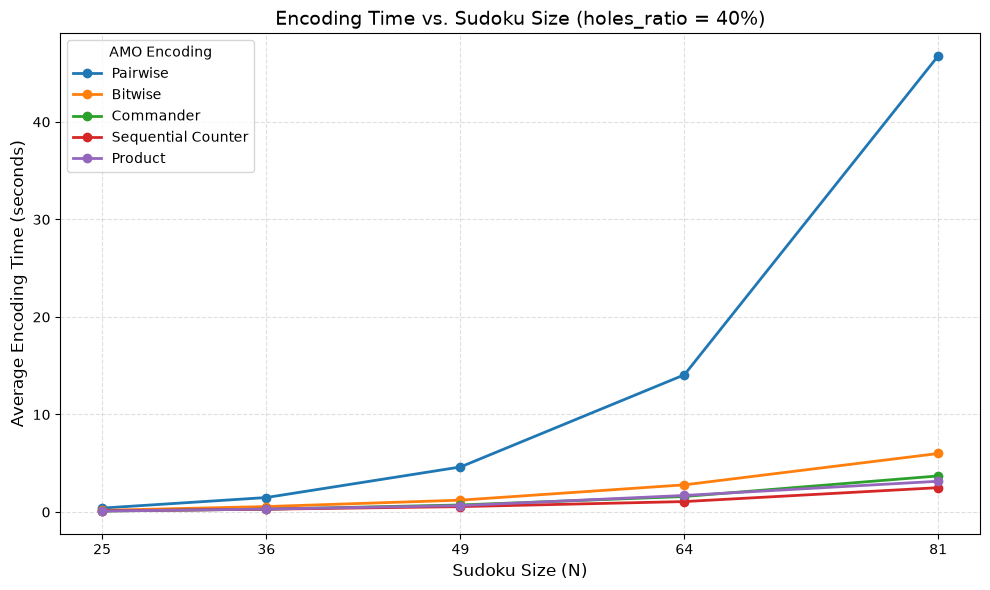

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path

OUTPUT_DIR = Path(r"C:\kì I 2026-2027\Các vấn đề hiện đại của KHMT\sudoku-sat-encodings\benchmarks\results")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

df = pd.read_csv("results\seed_sweep.csv")

sizes = [25, 36, 49, 64, 81]
holes_ratio = 0.40

methods = [
    "sat_pysat_pairwise",
    "sat_pysat_bitwise",
    "sat_commander",
    "sat_pysat_seqcounter",
    "sat_product"
]

method_names = {
    "sat_pysat_pairwise": "Pairwise",
    "sat_pysat_bitwise": "Bitwise",
    "sat_commander": "Commander",
    "sat_pysat_seqcounter": "Sequential Counter",
    "sat_product": "Product"
}

df["N"] = pd.to_numeric(df["N"], errors="coerce")
df["seed"] = pd.to_numeric(df["seed"], errors="coerce")
df["holes_ratio"] = pd.to_numeric(
    df["holes_ratio"], errors="coerce"
)
df["encode_time"] = pd.to_numeric(
    df["encode_time"], errors="coerce"
)

data = df[
    df["N"].isin(sizes)
    & df["method"].isin(methods)
    & np.isclose(df["holes_ratio"], holes_ratio)
].copy()

data = data.sort_values(["N", "method", "seed"])

data["_valid_time"] = data["encode_time"].notna()
data = (
    data.sort_values("_valid_time", ascending=False)
    .drop_duplicates(["N", "method", "seed"], keep="first")
    .drop(columns="_valid_time")
)

filled_groups = []

for (N, method), group in data.groupby(
    ["N", "method"], sort=False
):
    group = group.copy()

    valid = group[group["encode_time"].notna()].copy()
    valid = valid.sort_values("seed")

    if not valid.empty:
        missing_indices = group.index[
            group["encode_time"].isna()
        ]

        for idx in missing_indices:
            missing_seed = group.at[idx, "seed"]

            if pd.isna(missing_seed):
                continue

            candidates = valid.assign(
                distance=(valid["seed"] - missing_seed).abs()
            ).sort_values(["distance", "seed"])

            nearest_idx = candidates.index[0]
            nearest_seed = valid.at[nearest_idx, "seed"]
            nearest_time = valid.at[nearest_idx, "encode_time"]

            group.at[idx, "encode_time"] = nearest_time

            print(
                f"N={N}, method={method}, "
                f"seed={missing_seed}: dùng encode_time "
                f"của seed={nearest_seed} ({nearest_time:.6f}s)"
            )

    filled_groups.append(group)

data = pd.concat(filled_groups, ignore_index=True)

data = data.sort_values(
    ["N", "method", "seed"]
).reset_index(drop=True)

summary = (
    data.groupby(["N", "method"], as_index=False)
    .agg(
        mean_encode_time=("encode_time", "mean"),
        n_seeds=("seed", "nunique")
    )
)

summary = summary[summary["n_seeds"] == 3].copy()

print("Số cấu hình hợp lệ:", len(summary))
print("\nBảng thời gian mã hóa trung bình:")
print(
    summary.pivot(
        index="N",
        columns="method",
        values="mean_encode_time"
    ).reindex(sizes).round(5)
)

fig, ax = plt.subplots(figsize=(10, 6))

for method in methods:
    d = (
        summary[summary["method"] == method]
        .sort_values("N")
    )

    if not d.empty:
        ax.plot(
            d["N"],
            d["mean_encode_time"],
            marker="o",
            markersize=6,
            linewidth=2,
            label=method_names[method]
        )

ax.set_title(
    f"Encoding Time vs. Sudoku Size "
    f"(holes_ratio = {holes_ratio:.0%})",
    fontsize=14
)
ax.set_xlabel("Sudoku Size (N)", fontsize=12)
ax.set_ylabel("Average Encoding Time (seconds)", fontsize=12)
ax.set_xticks(sizes)
ax.grid(True, linestyle="--", alpha=0.4)
ax.legend(title="AMO Encoding")
fig.tight_layout()

fig.savefig(
    OUTPUT_DIR / "amo_encoding_time_vs_size.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

<>:11: SyntaxWarning: invalid escape sequence '\s'
<>:11: SyntaxWarning: invalid escape sequence '\s'
C:\Users\ASUS\AppData\Local\Temp\ipykernel_19436\2912816272.py:11: SyntaxWarning: invalid escape sequence '\s'
  df = pd.read_csv("results\seed_sweep.csv")


Số lượt theo trạng thái tại holes_ratio = 0.30:
status  SOLVED
N             
25          15
36          15
49          15
64          15
81          15

Bảng thời gian giải:
 N               method  mean_solve_time  median_solve_time  n_solved
25        sat_commander         0.102433             0.0938         3
36        sat_commander         0.234200             0.2336         3
49        sat_commander         0.621000             0.6206         3
64        sat_commander         1.465200             1.3986         3
81        sat_commander         3.178500             2.7982         3
25          sat_product         0.114967             0.1110         3
36          sat_product         0.276333             0.2435         3
49          sat_product         0.593400             0.6012         3
64          sat_product         1.314600             1.2558         3
81          sat_product         2.818833             2.4892         3
25    sat_pysat_bitwise         0.136667             0.

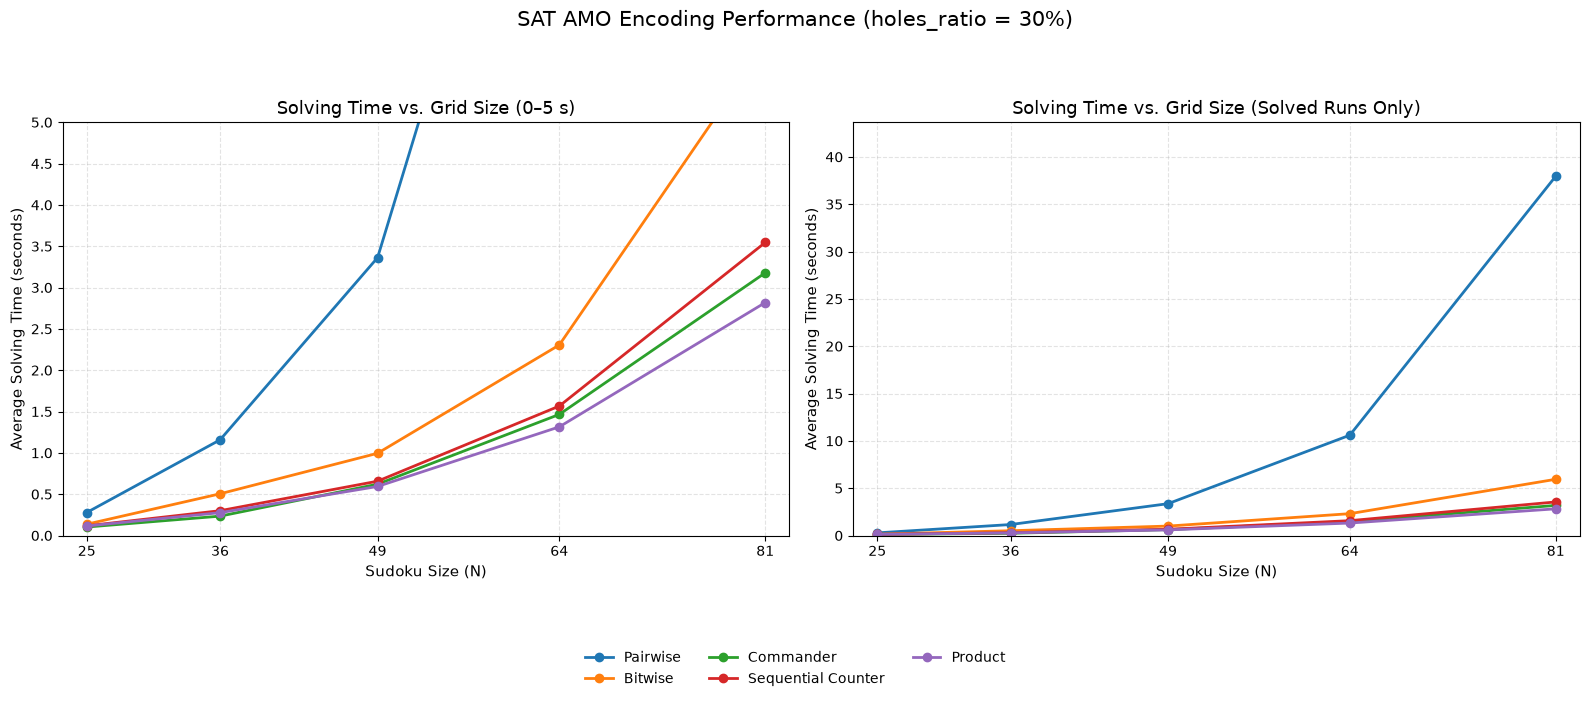

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

from pathlib import Path

OUTPUT_DIR = Path(r"C:\kì I 2026-2027\Các vấn đề hiện đại của KHMT\sudoku-sat-encodings\benchmarks\results")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

df = pd.read_csv("results\seed_sweep.csv")

sizes = [25, 36, 49, 64, 81]

methods = [
    "sat_pysat_pairwise",
    "sat_pysat_bitwise",
    "sat_commander",
    "sat_pysat_seqcounter",
    "sat_product"
]

method_names = {
    "sat_pysat_pairwise": "Pairwise",
    "sat_pysat_bitwise": "Bitwise",
    "sat_commander": "Commander",
    "sat_pysat_seqcounter": "Sequential Counter",
    "sat_product": "Product"
}

df["N"] = pd.to_numeric(df["N"], errors="coerce")
df["seed"] = pd.to_numeric(df["seed"], errors="coerce")
df["holes_ratio"] = pd.to_numeric(
    df["holes_ratio"], errors="coerce"
)
df["solve_time"] = pd.to_numeric(
    df["solve_time"], errors="coerce"
)

if "status" not in df.columns:
    raise ValueError("Không tìm thấy cột 'status' trong dữ liệu.")

holes_ratio = 0.30

data = df[
    df["N"].isin(sizes)
    & df["method"].isin(methods)
    & np.isclose(df["holes_ratio"], holes_ratio)
].copy()

data["status"] = (
    data["status"]
    .astype(str)
    .str.strip()
    .str.upper()
    .str.replace(r"[\s-]+", "_", regex=True)
)

print("Số lượt theo trạng thái tại holes_ratio = 0.30:")
print(
    data.groupby(["N", "status"])
    .size()
    .unstack(fill_value=0)
)

solved_statuses = {"SOLVED", "SAT"}

solved_data = data[
    data["status"].isin(solved_statuses)
].copy()

solved_data = solved_data[
    solved_data["solve_time"].notna()
    & (solved_data["solve_time"] >= 0)
].copy()

summary = (
    solved_data
    .groupby(["N", "method"], as_index=False)
    .agg(
        mean_solve_time=("solve_time", "mean"),
        median_solve_time=("solve_time", "median"),
        n_solved=("solve_time", "count")
    )
)

all_groups = pd.MultiIndex.from_product(
    [sizes, methods],
    names=["N", "method"]
).to_frame(index=False)

summary = all_groups.merge(
    summary,
    on=["N", "method"],
    how="left"
)

summary["n_solved"] = (
    summary["n_solved"].fillna(0).astype(int)
)

summary = summary.sort_values(["method", "N"])

print("\nBảng thời gian giải:")
print(summary.to_string(index=False))

summary.to_csv(
    "solving_time_summary_holes_030.csv",
    index=False
)

fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))

y_limits = [(0, 5), None]

titles = [
    "Solving Time vs. Grid Size (0–5 s)",
    "Solving Time vs. Grid Size (Solved Runs Only)"
]

for ax, y_limit, title in zip(axes, y_limits, titles):

    for method in methods:
        d = (
            summary[summary["method"] == method]
            .sort_values("N")
        )

        valid = d["mean_solve_time"].notna()

        if valid.any():
            ax.plot(
                d.loc[valid, "N"],
                d.loc[valid, "mean_solve_time"],
                marker="o",
                markersize=6,
                linewidth=2,
                label=method_names[method]
            )

    ax.set_title(title, fontsize=13)
    ax.set_xlabel("Sudoku Size (N)", fontsize=11)
    ax.set_ylabel(
        "Average Solving Time (seconds)",
        fontsize=11
    )
    ax.set_xticks(sizes)
    ax.set_xlim(23, 83)
    ax.grid(True, linestyle="--", alpha=0.35)

axes[0].set_ylim(0, 5)
axes[0].set_yticks(np.arange(0, 5.5, 0.5))

max_time = summary["mean_solve_time"].max()

if pd.notna(max_time) and max_time > 0:
    axes[1].set_ylim(0, max_time * 1.15)
else:
    axes[1].set_ylim(0, 1)

handles, labels = axes[1].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc="lower center",
    ncol=3,
    bbox_to_anchor=(0.5, -0.04),
    frameon=False
)

fig.suptitle(
    "SAT AMO Encoding Performance "
    f"(holes_ratio = {holes_ratio:.0%})",
    fontsize=15,
    y=1.02
)

fig.tight_layout(rect=[0, 0.12, 1, 0.96])

save_path = OUTPUT_DIR / "solving_time_two_views_holes_030.png"

fig.savefig(
    save_path,
    dpi=300,
    bbox_inches="tight"
)

print(f"\nĐã lưu biểu đồ: {save_path}")
print("Đã lưu bảng: solving_time_summary_holes_030.csv")

plt.show()

<>:10: SyntaxWarning: invalid escape sequence '\s'
<>:10: SyntaxWarning: invalid escape sequence '\s'
C:\Users\ASUS\AppData\Local\Temp\ipykernel_19436\1614510276.py:10: SyntaxWarning: invalid escape sequence '\s'
  df = pd.read_csv("results\seed_sweep.csv")


Đã lưu biểu đồ tại: C:\kì I 2026-2027\Các vấn đề hiện đại của KHMT\sudoku-sat-encodings\benchmarks\results\encoding_time_vs_hole_ratio.png


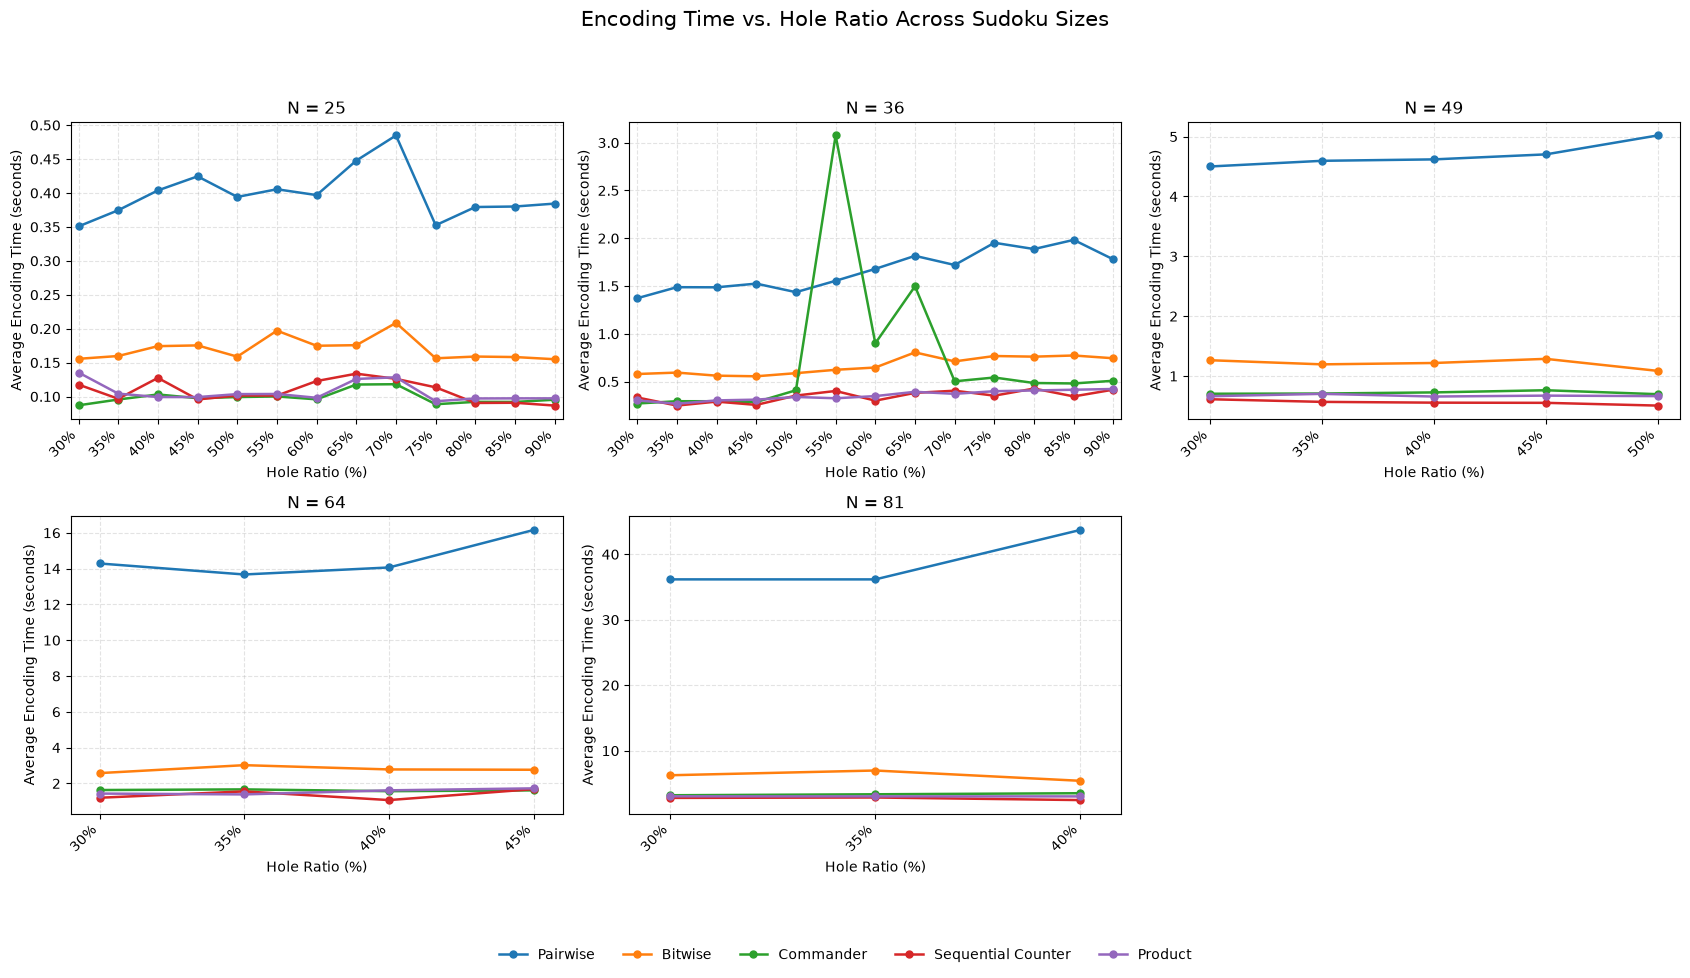

In [5]:
import os
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path

OUTPUT_DIR = Path(r"C:\kì I 2026-2027\Các vấn đề hiện đại của KHMT\sudoku-sat-encodings\benchmarks\results")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

df = pd.read_csv("results\seed_sweep.csv")

sizes = [25, 36, 49, 64, 81]

methods = [
    "sat_pysat_pairwise",
    "sat_pysat_bitwise",
    "sat_commander",
    "sat_pysat_seqcounter",
    "sat_product"
]

method_names = {
    "sat_pysat_pairwise": "Pairwise",
    "sat_pysat_bitwise": "Bitwise",
    "sat_commander": "Commander",
    "sat_pysat_seqcounter": "Sequential Counter",
    "sat_product": "Product"
}

for col in ["N", "seed", "holes_ratio", "encode_time"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

data = df[
    df["N"].isin(sizes)
    & df["method"].isin(methods)
    & df["holes_ratio"].notna()
    & df["encode_time"].notna()
].copy()

summary = (
    data.groupby(
        ["N", "holes_ratio", "method"],
        as_index=False
    )
    .agg(
        mean_encode_time=("encode_time", "mean"),
        n_runs=("encode_time", "count")
    )
)

fig, axes = plt.subplots(
    2, 3,
    figsize=(17, 10),
    sharex=False, 
    sharey=False
)

axes = axes.flatten()

for i, N in enumerate(sizes):
    ax = axes[i]
    subset_N = summary[summary["N"] == N]

    for method in methods:
        d = subset_N[
            subset_N["method"] == method
        ].sort_values("holes_ratio")

        if not d.empty:
            ax.plot(
                d["holes_ratio"] * 100,
                d["mean_encode_time"],
                marker="o",
                markersize=5,
                linewidth=1.8,
                label=method_names[method]
            )

    ratios = sorted(
        data.loc[
            data["N"] == N, "holes_ratio"
        ].dropna().unique()
    )

    ax.set_xticks([r * 100 for r in ratios])
    ax.set_xticklabels(
        [f"{r * 100:g}%" for r in ratios],
        rotation=45,
        ha="right"
    )

    ax.set_xlim(
        min(ratios) * 100 - 1 if ratios else 0,
        max(ratios) * 100 + 1 if ratios else 100
    )

    ax.set_title(f"N = {N}", fontsize=12)
    ax.set_xlabel("Hole Ratio (%)")
    ax.set_ylabel("Average Encoding Time (seconds)")
    ax.grid(True, linestyle="--", alpha=0.35)

fig.delaxes(axes[5])

handles, labels = axes[0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc="lower center",
    ncol=5,
    bbox_to_anchor=(0.5, 0.015),
    frameon=False
)

fig.suptitle(
    "Encoding Time vs. Hole Ratio Across Sudoku Sizes",
    fontsize=15,
    y=0.98
)

fig.tight_layout(rect=[0, 0.10, 1, 0.94])

save_path = OUTPUT_DIR / "encoding_time_vs_hole_ratio.png"

fig.savefig(save_path, dpi=300, bbox_inches="tight")
print(f"Đã lưu biểu đồ tại: {save_path}")

plt.show()

<>:12: SyntaxWarning: invalid escape sequence '\s'
<>:12: SyntaxWarning: invalid escape sequence '\s'
C:\Users\ASUS\AppData\Local\Temp\ipykernel_19436\469329244.py:12: SyntaxWarning: invalid escape sequence '\s'
  df = pd.read_csv("results\seed_sweep.csv")


=== Số lượt theo N và trạng thái trước khi loại ===
status  SKIPPED  SOLVED  TIMEOUT
N                               
25            0     195        0
36            0     192        3
49           10      45       20
64           10      30       20
81            5      30       10

=== Số lượt được giữ lại để tính thời gian ===
status  SOLVED
N             
25         195
36         192
49          45
64          30
81          30

=== Số lượt giải thành công theo N và AMO ===
method  sat_commander  sat_product  sat_pysat_bitwise  sat_pysat_pairwise  \
N                                                                           
25                 39           39                 39                  39   
36                 39           39                 39                  39   
49                  9            9                  9                   9   
64                  6            6                  6                   6   
81                  6            6                  6  

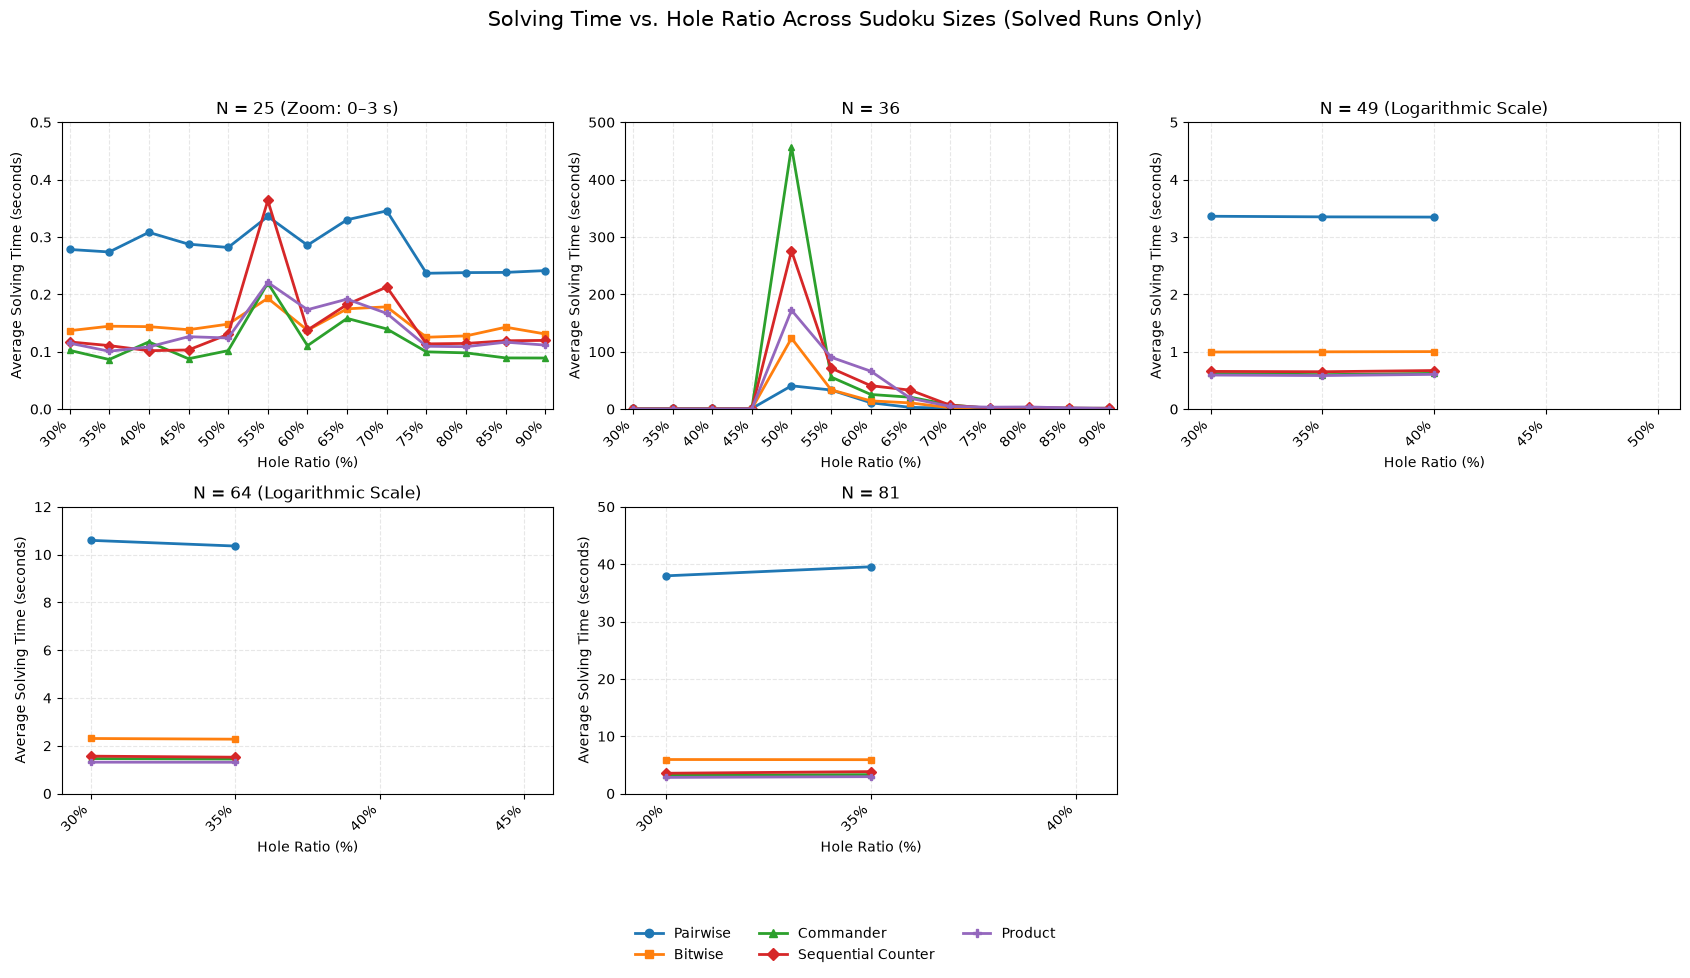

In [6]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

from pathlib import Path

OUTPUT_DIR = Path(r"C:\kì I 2026-2027\Các vấn đề hiện đại của KHMT\sudoku-sat-encodings\benchmarks\results")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

df = pd.read_csv("results\seed_sweep.csv")

sizes = [25, 36, 49, 64, 81]

methods = [
    "sat_pysat_pairwise",
    "sat_pysat_bitwise",
    "sat_commander",
    "sat_pysat_seqcounter",
    "sat_product"
]

method_names = {
    "sat_pysat_pairwise": "Pairwise",
    "sat_pysat_bitwise": "Bitwise",
    "sat_commander": "Commander",
    "sat_pysat_seqcounter": "Sequential Counter",
    "sat_product": "Product"
}

method_colors = {
    "sat_pysat_pairwise": "#1f77b4",
    "sat_pysat_bitwise": "#ff7f0e",
    "sat_commander": "#2ca02c",
    "sat_pysat_seqcounter": "#d62728",
    "sat_product": "#9467bd"
}

method_markers = {
    "sat_pysat_pairwise": "o",
    "sat_pysat_bitwise": "s",
    "sat_commander": "^",
    "sat_pysat_seqcounter": "D",
    "sat_product": "P"
}

required_columns = [
    "N", "seed", "holes_ratio", "method", "solve_time", "status"
]

missing_columns = [
    col for col in required_columns if col not in df.columns
]

if missing_columns:
    raise ValueError(
        f"CSV thiếu các cột cần thiết: {missing_columns}\n"
        f"Các cột hiện có: {df.columns.tolist()}"
    )

for col in ["N", "seed", "holes_ratio", "solve_time"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df["status"] = (
    df["status"]
    .astype(str)
    .str.strip()
    .str.upper()
    .str.replace(r"[\s-]+", "_", regex=True)
)

data = df[
    df["N"].isin(sizes)
    & df["method"].isin(methods)
    & df["holes_ratio"].notna()
].copy()

print("=== Số lượt theo N và trạng thái trước khi loại ===")
print(
    data.groupby(["N", "status"])
    .size()
    .unstack(fill_value=0)
)

solved_statuses = {"SOLVED", "SAT"}

solved_data = data[
    data["status"].isin(solved_statuses)
].copy()

solved_data = solved_data[
    solved_data["solve_time"].notna()
    & (solved_data["solve_time"] >= 0)
].copy()

print("\n=== Số lượt được giữ lại để tính thời gian ===")
print(
    solved_data.groupby(["N", "status"])
    .size()
    .unstack(fill_value=0)
)

print("\n=== Số lượt giải thành công theo N và AMO ===")
print(
    solved_data.groupby(["N", "method"])
    .size()
    .unstack(fill_value=0)
)

summary = (
    solved_data.groupby(
        ["N", "holes_ratio", "method"],
        as_index=False
    )
    .agg(
        mean_solve_time=("solve_time", "mean"),
        median_solve_time=("solve_time", "median"),
        n_solved=("solve_time", "count")
    )
)

ratios_by_size = (
    data.groupby("N")["holes_ratio"]
    .unique()
    .to_dict()
)

all_groups = []

for N in sizes:
    ratios = sorted(ratios_by_size.get(N, []))

    for ratio in ratios:
        for method in methods:
            all_groups.append({
                "N": N,
                "holes_ratio": ratio,
                "method": method
            })

all_groups = pd.DataFrame(
    all_groups,
    columns=["N", "holes_ratio", "method"]
)

summary = all_groups.merge(
    summary,
    on=["N", "holes_ratio", "method"],
    how="left"
)

summary["n_solved"] = (
    summary["n_solved"].fillna(0).astype(int)
)

summary = summary.sort_values(
    ["N", "method", "holes_ratio"]
)

# Lưu dữ liệu tổng hợp
summary.to_csv(
    "solving_time_vs_hole_ratio_summary_solved_only.csv",
    index=False
)

y_config = {
    25: {"scale": "linear", "ylim": (0, 0.5)},
    36: {"scale": "linear", "ylim": (0, 500)}, 
    49: {"scale": "linear", "ylim": (0, 5)},
    64: {"scale": "linear", "ylim": (0, 12)},
    81: {"scale": "linear", "ylim": (0, 50)},
}

fig, axes = plt.subplots(
    2, 3,
    figsize=(17, 10),
    sharex=False,
    sharey=False
)

axes = axes.flatten()

for i, N in enumerate(sizes):
    ax = axes[i]

    subset_N = summary[
        summary["N"] == N
    ].copy()

    config = y_config[N]

    ax.set_yscale(config["scale"])
    ax.set_ylim(*config["ylim"])

    for method in methods:
        d = (
            subset_N[subset_N["method"] == method]
            .sort_values("holes_ratio")
            .copy()
        )

        if d.empty:
            continue

        if config["scale"] == "log":
            d.loc[
                d["mean_solve_time"] <= 0,
                "mean_solve_time"
            ] = np.nan

        valid = d["mean_solve_time"].notna()

        if not valid.any():
            continue

        ax.plot(
            d.loc[valid, "holes_ratio"] * 100,
            d.loc[valid, "mean_solve_time"],
            color=method_colors[method],
            linestyle="-",
            marker=method_markers[method],
            markersize=5,
            linewidth=2,
            label=method_names[method]
        )

    ratios = sorted(
        data.loc[
            data["N"] == N,
            "holes_ratio"
        ].dropna().unique()
    )

    if ratios:
        ratio_percentages = np.array(ratios) * 100

        ax.set_xticks(ratio_percentages)
        ax.set_xticklabels(
            [f"{r * 100:g}%" for r in ratios],
            rotation=45,
            ha="right"
        )

        if len(ratio_percentages) == 1:
            ax.set_xlim(
                ratio_percentages[0] - 2,
                ratio_percentages[0] + 2
            )
        else:
            ax.set_xlim(
                ratio_percentages.min() - 1,
                ratio_percentages.max() + 1
            )

    if N == 25:
        title = "N = 25 (Zoom: 0–3 s)"
    elif N in [49, 64]:
        title = f"N = {N} (Logarithmic Scale)"
    else:
        title = f"N = {N}"

    ax.set_title(title, fontsize=12)
    ax.set_xlabel("Hole Ratio (%)")
    ax.set_ylabel("Average Solving Time (seconds)")

    ax.grid(
        True,
        which="both",
        linestyle="--",
        alpha=0.3
    )

fig.delaxes(axes[5])

legend_handles = [
    Line2D(
        [0], [0],
        color=method_colors[method],
        linestyle="-",
        marker=method_markers[method],
        linewidth=2,
        markersize=6,
        label=method_names[method]
    )
    for method in methods
]

fig.legend(
    handles=legend_handles,
    loc="lower center",
    ncol=3,
    bbox_to_anchor=(0.5, 0.015),
    frameon=False,
    fontsize=10
)

fig.suptitle(
    "Solving Time vs. Hole Ratio Across Sudoku Sizes "
    "(Solved Runs Only)",
    fontsize=15,
    y=0.98
)

fig.tight_layout(rect=[0, 0.12, 1, 0.94])

save_path = OUTPUT_DIR / "solving_time_vs_hole_ratio_detail_solved_only.png"

fig.savefig(
    save_path,
    dpi=300,
    bbox_inches="tight"
)

print(f"\nĐã lưu biểu đồ tại: {save_path}")
print(
    "Đã lưu bảng tổng hợp tại: "
    "solving_time_vs_hole_ratio_summary_solved_only.csv"
)

plt.show()

<>:12: SyntaxWarning: invalid escape sequence '\s'
<>:12: SyntaxWarning: invalid escape sequence '\s'
C:\Users\ASUS\AppData\Local\Temp\ipykernel_19436\1335449034.py:12: SyntaxWarning: invalid escape sequence '\s'
  INPUT_FILE = "results\seed_sweep.csv"


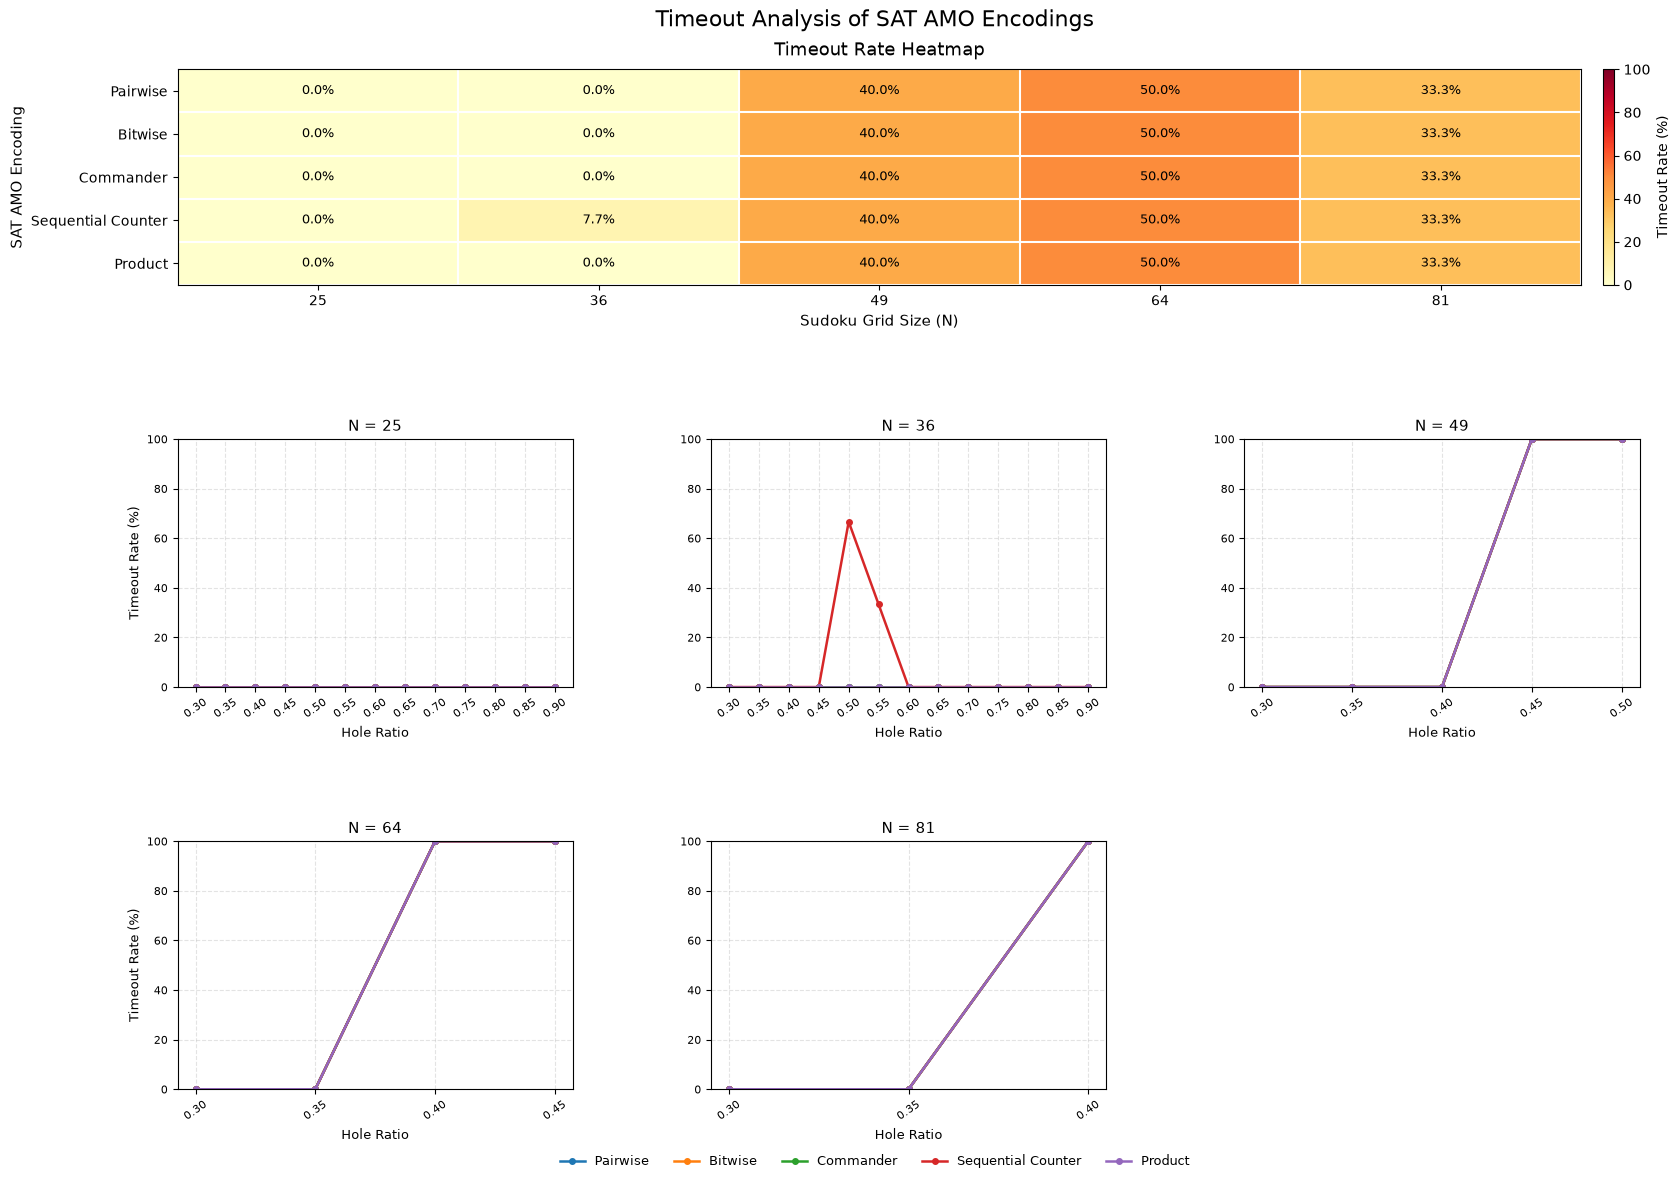

Combined figure saved to: C:\kì I 2026-2027\Các vấn đề hiện đại của KHMT\sudoku-sat-encodings\benchmarks\results\timeout_analysis.png
Summary table saved to: timeout_analysis_summary.csv


In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec

from pathlib import Path

OUTPUT_DIR = Path(r"C:\kì I 2026-2027\Các vấn đề hiện đại của KHMT\sudoku-sat-encodings\benchmarks\results")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)


INPUT_FILE = "results\seed_sweep.csv"
OUTPUT_FILE = OUTPUT_DIR / "timeout_analysis.png"
OUTPUT_CSV = "timeout_analysis_summary.csv"

GRID_SIZES = [25, 36, 49, 64, 81]

METHOD_ORDER = [
    "sat_pysat_pairwise",
    "sat_pysat_bitwise",
    "sat_commander",
    "sat_pysat_seqcounter",
    "sat_product",
]

METHOD_LABELS = {
    "sat_pysat_pairwise": "Pairwise",
    "sat_pysat_bitwise": "Bitwise",
    "sat_commander": "Commander",
    "sat_pysat_seqcounter": "Sequential Counter",
    "sat_product": "Product",
}

SUCCESS_STATUSES = {"SOLVED", "SAT"}
TIMEOUT_STATUSES = {"TIMEOUT", "SKIPPED"}


df = pd.read_csv(INPUT_FILE)

required = {"N", "holes_ratio", "method", "status"}
missing = required - set(df.columns)

if missing:
    raise ValueError(f"Missing columns: {sorted(missing)}")

df["N"] = pd.to_numeric(df["N"], errors="coerce")
df["holes_ratio"] = pd.to_numeric(
    df["holes_ratio"], errors="coerce"
)

df["method"] = df["method"].astype("string").str.strip()

df["status"] = (
    df["status"]
    .astype("string")
    .str.strip()
    .str.upper()
    .str.replace(r"[\s-]+", "_", regex=True)
    .replace({"TIME_OUT": "TIMEOUT"})
)

valid_statuses = SUCCESS_STATUSES | TIMEOUT_STATUSES

df = df[
    df["N"].isin(GRID_SIZES)
    & df["method"].isin(METHOD_ORDER)
    & df["status"].isin(valid_statuses)
].copy()

df["is_timeout"] = df["status"].isin(TIMEOUT_STATUSES)
df["is_solved"] = df["status"].isin(SUCCESS_STATUSES)

if df.empty:
    raise ValueError(
        "No valid rows found. Check the input file and status values."
    )

overall = (
    df.groupby(["N", "method"], observed=True)
    .agg(
        total_runs=("status", "size"),
        solved=("is_solved", "sum"),
        timeout=("status", lambda s: (s == "TIMEOUT").sum()),
        skipped=("status", lambda s: (s == "SKIPPED").sum()),
        total_timeout=("is_timeout", "sum"),
    )
    .reset_index()
)

overall["timeout_rate"] = (
    overall["total_timeout"] / overall["total_runs"] * 100
)

heatmap_data = (
    overall.pivot(
        index="method",
        columns="N",
        values="timeout_rate"
    )
    .reindex(index=METHOD_ORDER, columns=GRID_SIZES)
)

by_ratio = (
    df.dropna(subset=["holes_ratio"])
    .groupby(
        ["N", "holes_ratio", "method"],
        observed=True
    )
    .agg(
        total_runs=("status", "size"),
        total_timeout=("is_timeout", "sum"),
    )
    .reset_index()
)

by_ratio["timeout_rate"] = (
    by_ratio["total_timeout"] / by_ratio["total_runs"] * 100
)

overall["method_label"] = overall["method"].map(METHOD_LABELS)

overall[
    [
        "N", "method_label", "solved", "timeout", "skipped",
        "total_timeout", "total_runs", "timeout_rate"
    ]
].rename(columns={
    "method_label": "method",
    "solved": "solved_count",
    "timeout": "timeout_count",
    "skipped": "skipped_count",
    "total_timeout": "total_timeout_including_skipped",
    "total_runs": "total_runs_in_denominator",
    "timeout_rate": "timeout_rate_percent",
}).to_csv(OUTPUT_CSV, index=False)


fig = plt.figure(figsize=(17, 12))

gs = GridSpec(
    nrows=3,
    ncols=3,
    figure=fig,
    height_ratios=[1.0, 1.15, 1.15],
    hspace=0.65,
    wspace=0.35
)


ax_heat = fig.add_subplot(gs[0, :])

values = np.ma.masked_invalid(heatmap_data.to_numpy())

im = ax_heat.imshow(
    values,
    cmap="YlOrRd",
    vmin=0,
    vmax=100,
    aspect="auto"
)

ax_heat.set_xticks(range(len(GRID_SIZES)))
ax_heat.set_xticklabels(GRID_SIZES, fontsize=10)

ax_heat.set_yticks(range(len(METHOD_ORDER)))
ax_heat.set_yticklabels(
    [METHOD_LABELS[m] for m in METHOD_ORDER],
    fontsize=10
)

ax_heat.set_xlabel("Sudoku Grid Size (N)", fontsize=11)
ax_heat.set_ylabel("SAT AMO Encoding", fontsize=11)
ax_heat.set_title(
    "Timeout Rate Heatmap",
    fontsize=13,
    pad=10
)

for i in range(len(METHOD_ORDER)):
    for j in range(len(GRID_SIZES)):
        value = heatmap_data.iloc[i, j]

        if pd.notna(value):
            text_color = "white" if value >= 55 else "black"
            ax_heat.text(
                j, i, f"{value:.1f}%",
                ha="center",
                va="center",
                fontsize=9,
                color=text_color
            )
        else:
            ax_heat.text(
                j, i, "N/A",
                ha="center",
                va="center",
                fontsize=9,
                color="gray"
            )

ax_heat.set_xticks(
    np.arange(-0.5, len(GRID_SIZES), 1),
    minor=True
)
ax_heat.set_yticks(
    np.arange(-0.5, len(METHOD_ORDER), 1),
    minor=True
)
ax_heat.grid(which="minor", color="white", linewidth=1.5)
ax_heat.tick_params(which="minor", bottom=False, left=False)

cbar = fig.colorbar(
    im,
    ax=ax_heat,
    orientation="vertical",
    fraction=0.025,
    pad=0.015
)
cbar.set_label("Timeout Rate (%)", fontsize=10)
cbar.set_ticks([0, 20, 40, 60, 80, 100])


axes = [
    fig.add_subplot(gs[1, 0]),
    fig.add_subplot(gs[1, 1]),
    fig.add_subplot(gs[1, 2]),
    fig.add_subplot(gs[2, 0]),
    fig.add_subplot(gs[2, 1]),
]

colors = plt.rcParams["axes.prop_cycle"].by_key()["color"]

method_colors = {
    method: colors[i % len(colors)]
    for i, method in enumerate(METHOD_ORDER)
}

legend_handles = {}

for ax, N in zip(axes, GRID_SIZES):
    subset_N = by_ratio[by_ratio["N"] == N]

    for method in METHOD_ORDER:
        line_data = subset_N[
            subset_N["method"] == method
        ].sort_values("holes_ratio")

        if line_data.empty:
            continue

        line, = ax.plot(
            line_data["holes_ratio"],
            line_data["timeout_rate"],
            marker="o",
            markersize=4,
            linewidth=1.8,
            linestyle="-",
            color=method_colors[method],
            label=METHOD_LABELS[method]
        )

        legend_handles[METHOD_LABELS[method]] = line

    ax.set_title(f"N = {N}", fontsize=11)
    ax.set_xlabel("Hole Ratio", fontsize=9)
    ax.set_ylim(0, 100)
    ax.set_yticks([0, 20, 40, 60, 80, 100])
    ax.grid(True, linestyle="--", alpha=0.35)
    ax.tick_params(axis="both", labelsize=8)

    observed_ratios = sorted(
        subset_N["holes_ratio"].dropna().unique()
    )
    ax.set_xticks(observed_ratios)
    ax.tick_params(axis="x", rotation=35)

    if ax in [axes[0], axes[3]]:
        ax.set_ylabel("Timeout Rate (%)", fontsize=9)

    if subset_N.empty:
        ax.text(
            0.5, 0.5, "No data",
            ha="center",
            va="center",
            transform=ax.transAxes
        )

ax_empty = fig.add_subplot(gs[2, 2])
ax_empty.axis("off")

fig.legend(
    legend_handles.values(),
    legend_handles.keys(),
    loc="lower center",
    ncol=5,
    frameon=False,
    fontsize=9,
    bbox_to_anchor=(0.5, 0.015)
)

fig.suptitle(
    "Timeout Analysis of SAT AMO Encodings",
    fontsize=16,
    y=0.99
)

fig.subplots_adjust(
    top=0.94,
    bottom=0.09,
    left=0.09,
    right=0.95
)

fig.savefig(
    OUTPUT_FILE,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

print(f"Combined figure saved to: {OUTPUT_FILE}")
print(f"Summary table saved to: {OUTPUT_CSV}")

<>:10: SyntaxWarning: invalid escape sequence '\s'
<>:10: SyntaxWarning: invalid escape sequence '\s'
C:\Users\ASUS\AppData\Local\Temp\ipykernel_19436\4129819714.py:10: SyntaxWarning: invalid escape sequence '\s'
  INPUT_FILE = "results\seed_sweep.csv"


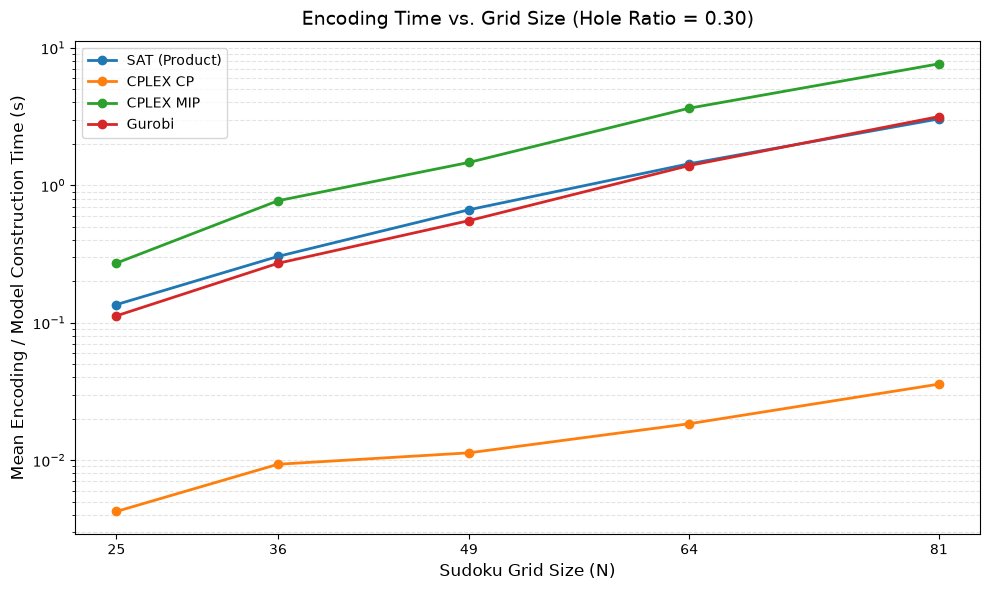


Mean encoding/model construction time (seconds):
method_label  SAT (Product)  CPLEX CP  CPLEX MIP  Gurobi
N                                                       
25                   0.1354    0.0042     0.2714  0.1122
36                   0.3034    0.0093     0.7714  0.2704
49                   0.6630    0.0113     1.4653  0.5523
64                   1.4331    0.0184     3.6350  1.3908
81                   3.0382    0.0357     7.6448  3.1587

Figure saved to: C:\kì I 2026-2027\Các vấn đề hiện đại của KHMT\sudoku-sat-encodings\benchmarks\results\encoding_time_product_vs_cp_ilp_rho_030.png
Summary CSV saved to: encoding_time_product_vs_cp_ilp_rho_030.csv

Number of successful observations per method and N:
method_label  CPLEX CP  CPLEX MIP  Gurobi  SAT (Product)
N                                                       
25                   3          3       3              3
36                   3          3       3              3
49                   3          3       3              

In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path

OUTPUT_DIR = Path(r"C:\kì I 2026-2027\Các vấn đề hiện đại của KHMT\sudoku-sat-encodings\benchmarks\results")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

INPUT_FILE = "results\seed_sweep.csv"

OUTPUT_FIGURE = OUTPUT_DIR / "encoding_time_product_vs_cp_ilp_rho_030.png"
OUTPUT_CSV = "encoding_time_product_vs_cp_ilp_rho_030.csv"

GRID_SIZES = [25, 36, 49, 64, 81]
TARGET_HOLE_RATIO = 0.30

METHOD_LABELS = {
    "sat_product": "SAT (Product)",
    "cplex_cp": "CPLEX CP",
    "cplex_mip": "CPLEX MIP",
    "gurobi": "Gurobi",
}

METHOD_ORDER = list(METHOD_LABELS.keys())

df = pd.read_csv(INPUT_FILE)

required_columns = {
    "N", "holes_ratio", "seed",
    "method", "status", "encode_time"
}

missing_columns = required_columns - set(df.columns)

if missing_columns:
    raise ValueError(
        f"Missing required columns: {sorted(missing_columns)}"
    )

df["N"] = pd.to_numeric(df["N"], errors="coerce")
df["holes_ratio"] = pd.to_numeric(
    df["holes_ratio"], errors="coerce"
)
df["encode_time"] = pd.to_numeric(
    df["encode_time"], errors="coerce"
)

df["method"] = df["method"].astype(str).str.strip()

df["status"] = (
    df["status"]
    .astype(str)
    .str.strip()
    .str.upper()
)

data = df[
    df["N"].isin(GRID_SIZES)
    & np.isclose(
        df["holes_ratio"],
        TARGET_HOLE_RATIO,
        atol=1e-8
    )
    & df["method"].isin(METHOD_ORDER)
    & df["status"].isin(["SOLVED", "SAT"])
    & df["encode_time"].notna()
    & (df["encode_time"] >= 0)
].copy()

if data.empty:
    raise ValueError(
        "No successful observations found for hole_ratio = 0.30. "
        "Please check the input CSV."
    )

summary = (
    data.groupby(["N", "method"], as_index=False)
    .agg(
        mean_encode_time=("encode_time", "mean"),
        std_encode_time=("encode_time", "std"),
        n_solved=("encode_time", "count"),
    )
)

expected = pd.MultiIndex.from_product(
    [GRID_SIZES, METHOD_ORDER],
    names=["N", "method"]
)

summary = (
    summary.set_index(["N", "method"])
    .reindex(expected)
    .reset_index()
)

summary["method_label"] = summary["method"].map(METHOD_LABELS)

summary.to_csv(OUTPUT_CSV, index=False)

fig, ax = plt.subplots(figsize=(10, 6))

for method in METHOD_ORDER:
    method_data = (
        summary[summary["method"] == method]
        .sort_values("N")
    )

    valid = (
        method_data["mean_encode_time"].notna()
        & (method_data["mean_encode_time"] > 0)
    )

    method_data = method_data[valid]

    if method_data.empty:
        print(f"Warning: no valid data for {METHOD_LABELS[method]}")
        continue

    ax.plot(
        method_data["N"],
        method_data["mean_encode_time"],
        marker="o",
        markersize=6,
        linewidth=2,
        label=METHOD_LABELS[method],
    )

ax.set_yscale("log")

ax.set_xticks(GRID_SIZES)
ax.set_xlabel("Sudoku Grid Size (N)", fontsize=12)
ax.set_ylabel(
    "Mean Encoding / Model Construction Time (s)",
    fontsize=12
)

ax.set_title(
    "Encoding Time vs. Grid Size (Hole Ratio = 0.30)",
    fontsize=14,
    pad=12
)

ax.grid(
    True,
    which="both",
    axis="y",
    linestyle="--",
    alpha=0.35
)

ax.legend(
    loc="best",
    frameon=True,
    fontsize=10
)

fig.tight_layout()

fig.savefig(
    OUTPUT_FIGURE,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

table = summary.pivot(
    index="N",
    columns="method_label",
    values="mean_encode_time"
)

table = table.reindex(
    index=GRID_SIZES,
    columns=[METHOD_LABELS[m] for m in METHOD_ORDER]
)

print("\nMean encoding/model construction time (seconds):")
print(table.round(4).to_string())

print(f"\nFigure saved to: {OUTPUT_FIGURE}")
print(f"Summary CSV saved to: {OUTPUT_CSV}")

print("\nNumber of successful observations per method and N:")
print(
    summary.pivot(
        index="N",
        columns="method_label",
        values="n_solved"
    ).to_string()
)

<>:10: SyntaxWarning: invalid escape sequence '\s'
<>:10: SyntaxWarning: invalid escape sequence '\s'
C:\Users\ASUS\AppData\Local\Temp\ipykernel_19436\2829003754.py:10: SyntaxWarning: invalid escape sequence '\s'
  INPUT_FILE = "results\seed_sweep.csv"


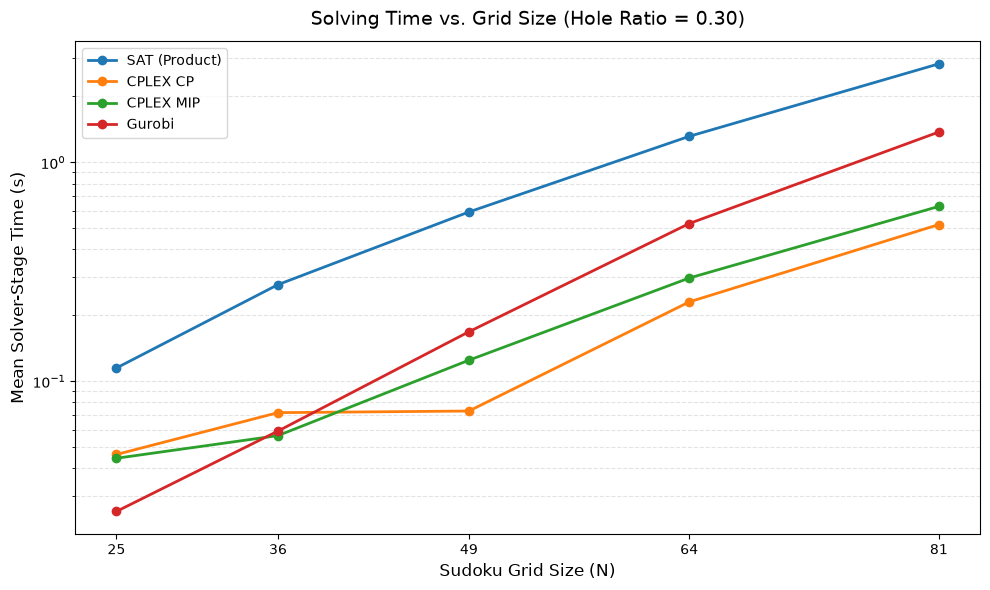


Mean solver-stage time (seconds):
method_label  SAT (Product)  CPLEX CP  CPLEX MIP  Gurobi
N                                                       
25                   0.1150    0.0463     0.0445  0.0254
36                   0.2763    0.0719     0.0565  0.0592
49                   0.5934    0.0731     0.1248  0.1683
64                   1.3146    0.2304     0.2962  0.5254
81                   2.8188    0.5199     0.6293  1.3762

Number of successful runs per method and grid size:
method_label  SAT (Product)  CPLEX CP  CPLEX MIP  Gurobi
N                                                       
25                        3         3          3       3
36                        3         3          3       3
49                        3         3          3       3
64                        3         3          3       3
81                        3         3          3       3

Figure saved to: C:\kì I 2026-2027\Các vấn đề hiện đại của KHMT\sudoku-sat-encodings\benchmarks\results\solving_t

In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path

OUTPUT_DIR = Path(r"C:\kì I 2026-2027\Các vấn đề hiện đại của KHMT\sudoku-sat-encodings\benchmarks\results")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

INPUT_FILE = "results\seed_sweep.csv"

OUTPUT_FIGURE = OUTPUT_DIR / "solving_time_product_vs_cp_ilp_rho_030.png"
OUTPUT_CSV = "solving_time_product_vs_cp_ilp_rho_030.csv"

GRID_SIZES = [25, 36, 49, 64, 81]
TARGET_HOLE_RATIO = 0.30

METHOD_LABELS = {
    "sat_product": "SAT (Product)",
    "cplex_cp": "CPLEX CP",
    "cplex_mip": "CPLEX MIP",
    "gurobi": "Gurobi",
}

METHOD_ORDER = list(METHOD_LABELS.keys())

df = pd.read_csv(INPUT_FILE)

required_columns = {
    "N", "holes_ratio", "seed",
    "method", "status", "solve_time"
}

missing_columns = required_columns - set(df.columns)

if missing_columns:
    raise ValueError(
        f"Missing required columns: {sorted(missing_columns)}"
    )

df["N"] = pd.to_numeric(df["N"], errors="coerce")
df["holes_ratio"] = pd.to_numeric(
    df["holes_ratio"], errors="coerce"
)
df["solve_time"] = pd.to_numeric(
    df["solve_time"], errors="coerce"
)

df["method"] = df["method"].astype(str).str.strip()

df["status"] = (
    df["status"]
    .astype(str)
    .str.strip()
    .str.upper()
    .str.replace(r"[\s-]+", "_", regex=True)
)

data = df[
    df["N"].isin(GRID_SIZES)
    & np.isclose(
        df["holes_ratio"],
        TARGET_HOLE_RATIO,
        atol=1e-8
    )
    & df["method"].isin(METHOD_ORDER)
    & df["status"].isin(["SOLVED", "SAT"])
    & df["solve_time"].notna()
    & (df["solve_time"] >= 0)
].copy()

if data.empty:
    raise ValueError(
        "No successful observations found at holes_ratio = 0.30. "
        "Check the CSV file, method names and status values."
    )

summary = (
    data.groupby(["N", "method"], as_index=False)
    .agg(
        mean_solve_time=("solve_time", "mean"),
        std_solve_time=("solve_time", "std"),
        n_solved=("solve_time", "count"),
    )
)

expected = pd.MultiIndex.from_product(
    [GRID_SIZES, METHOD_ORDER],
    names=["N", "method"]
)

summary = (
    summary.set_index(["N", "method"])
    .reindex(expected)
    .reset_index()
)

summary["method_label"] = summary["method"].map(METHOD_LABELS)

summary.to_csv(OUTPUT_CSV, index=False)

fig, ax = plt.subplots(figsize=(10, 6))

for method in METHOD_ORDER:
    method_data = (
        summary[summary["method"] == method]
        .sort_values("N")
        .copy()
    )

    valid = (
        method_data["mean_solve_time"].notna()
        & (method_data["mean_solve_time"] > 0)
    )

    method_data = method_data[valid]

    if method_data.empty:
        print(f"Warning: no valid data for {METHOD_LABELS[method]}")
        continue

    ax.plot(
        method_data["N"],
        method_data["mean_solve_time"],
        marker="o",
        markersize=6,
        linewidth=2,
        label=METHOD_LABELS[method],
    )

ax.set_yscale("log")

ax.set_xticks(GRID_SIZES)
ax.set_xlabel("Sudoku Grid Size (N)", fontsize=12)
ax.set_ylabel("Mean Solver-Stage Time (s)", fontsize=12)

ax.set_title(
    "Solving Time vs. Grid Size (Hole Ratio = 0.30)",
    fontsize=14,
    pad=12
)

ax.grid(
    True,
    which="both",
    axis="y",
    linestyle="--",
    alpha=0.35
)

ax.legend(
    loc="best",
    frameon=True,
    fontsize=10
)

fig.tight_layout()

fig.savefig(
    OUTPUT_FIGURE,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

table = summary.pivot(
    index="N",
    columns="method_label",
    values="mean_solve_time"
)

table = table.reindex(
    index=GRID_SIZES,
    columns=[METHOD_LABELS[m] for m in METHOD_ORDER]
)

print("\nMean solver-stage time (seconds):")
print(table.round(4).to_string())

print("\nNumber of successful runs per method and grid size:")
count_table = summary.pivot(
    index="N",
    columns="method_label",
    values="n_solved"
).reindex(
    index=GRID_SIZES,
    columns=[METHOD_LABELS[m] for m in METHOD_ORDER]
)

print(count_table.to_string())

print(f"\nFigure saved to: {OUTPUT_FIGURE}")
print(f"Summary CSV saved to: {OUTPUT_CSV}")

<>:6: SyntaxWarning: invalid escape sequence '\s'
<>:6: SyntaxWarning: invalid escape sequence '\s'
C:\Users\ASUS\AppData\Local\Temp\ipykernel_19436\1977322416.py:6: SyntaxWarning: invalid escape sequence '\s'
  INPUT_FILE = "results\seed_sweep.csv"


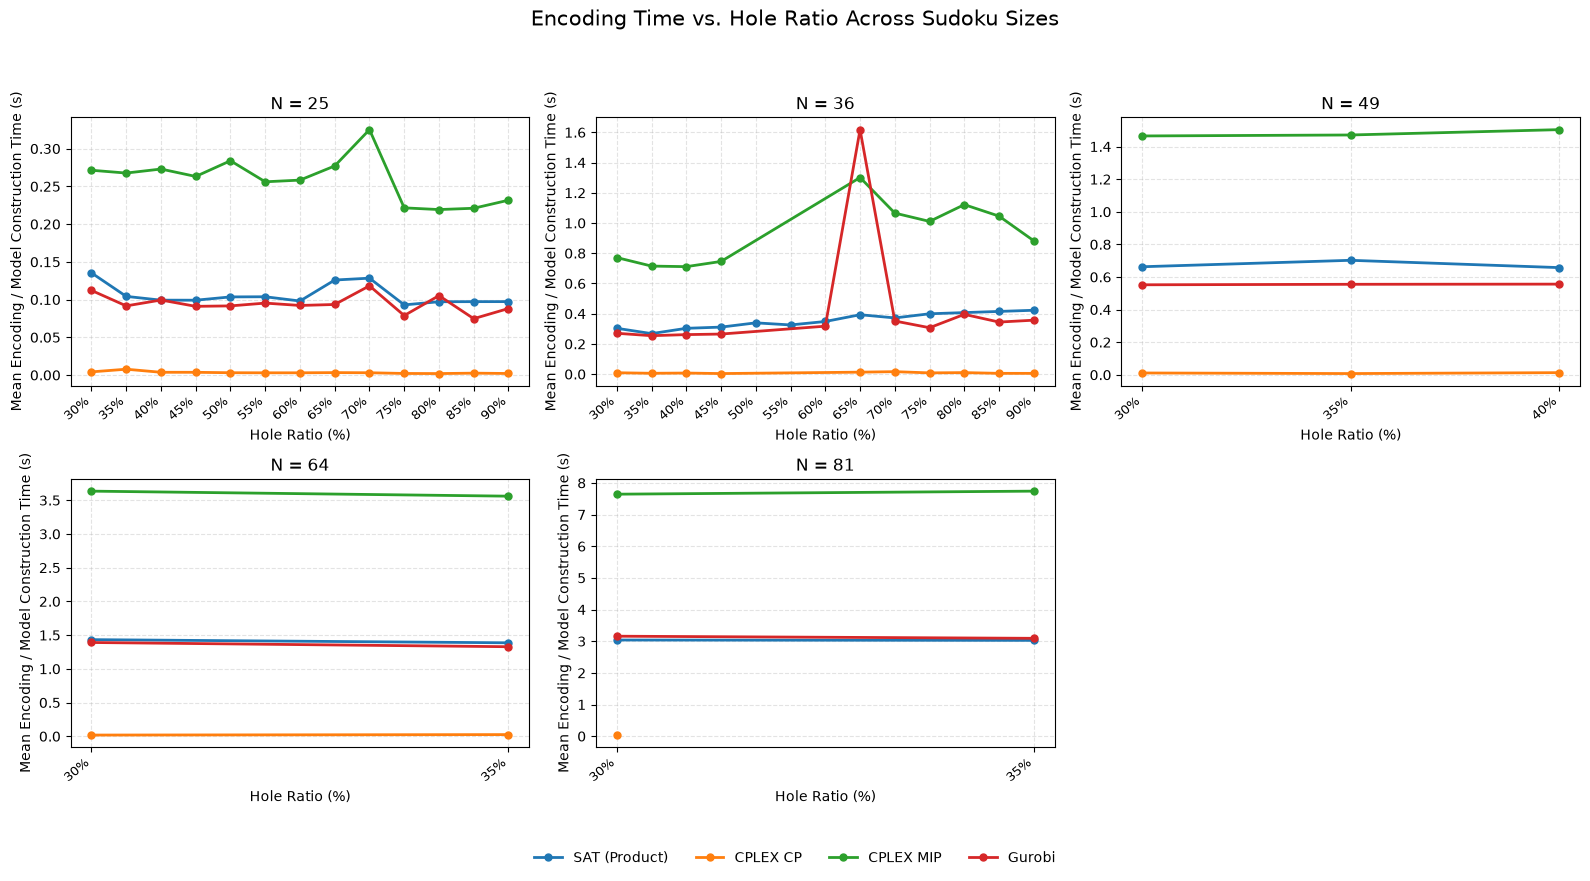

Mean encoding/model construction time (seconds):
method_label    CPLEX CP  CPLEX MIP  Gurobi  SAT (Product)
N  holes_ratio                                            
25 0.30           0.0042     0.2714  0.1122         0.1354
   0.35           0.0078     0.2677  0.0917         0.1043
   0.40           0.0037     0.2730  0.0994         0.0993
   0.45           0.0037     0.2632  0.0911         0.0992
   0.50           0.0031     0.2840  0.0917         0.1036
   0.55           0.0030     0.2561  0.0954         0.1038
   0.60           0.0030     0.2583  0.0922         0.0981
   0.65           0.0033     0.2771  0.0935         0.1259
   0.70           0.0031     0.3252  0.1183         0.1284
   0.75           0.0021     0.2216  0.0789         0.0930
   0.80           0.0020     0.2193  0.1053         0.0972
   0.85           0.0025     0.2210  0.0747         0.0973
   0.90           0.0021     0.2317  0.0882         0.0973
36 0.30           0.0093     0.7714  0.2704         0.3034
   0.35

In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

INPUT_FILE = "results\seed_sweep.csv"

IMAGE_DIR = Path(r"C:\kì I 2026-2027\Các vấn đề hiện đại của KHMT\sudoku-sat-encodings\benchmarks\results")
IMAGE_DIR.mkdir(parents=True, exist_ok=True)
CSV_DIR = Path(INPUT_FILE).resolve().parent

OUTPUT_FIGURE = IMAGE_DIR / "encoding_time_product_vs_cp_ilp_by_hole_ratio.png"
OUTPUT_CSV = CSV_DIR / "encoding_time_product_vs_cp_ilp_by_hole_ratio.csv"

GRID_SIZES = [25, 36, 49, 64, 81]

METHOD_LABELS = {
    "sat_product": "SAT (Product)",
    "cplex_cp": "CPLEX CP",
    "cplex_mip": "CPLEX MIP",
    "gurobi": "Gurobi",
}

METHOD_ORDER = [
    "sat_product",
    "cplex_cp",
    "cplex_mip",
    "gurobi",
]

SUCCESS_STATUSES = {"SOLVED", "SAT", "FEASIBLE", "OPTIMAL"}

df = pd.read_csv(INPUT_FILE)

required_columns = {
    "N", "holes_ratio", "seed",
    "method", "status", "encode_time"
}

missing_columns = required_columns - set(df.columns)

if missing_columns:
    raise ValueError(
        f"CSV is missing required columns: {sorted(missing_columns)}"
    )

df["N"] = pd.to_numeric(df["N"], errors="coerce")
df["holes_ratio"] = pd.to_numeric(
    df["holes_ratio"], errors="coerce"
)
df["encode_time"] = pd.to_numeric(
    df["encode_time"], errors="coerce"
)

df["method"] = (
    df["method"].astype("string").str.strip().str.lower()
)

df["status"] = (
    df["status"]
    .astype("string")
    .str.strip()
    .str.upper()
    .str.replace(r"[\s-]+", "_", regex=True)
)

df["status"] = df["status"].replace({
    "TIME_OUT": "TIMEOUT",
})

valid_ratios = df["holes_ratio"].dropna()
if not valid_ratios.empty and valid_ratios.max() > 1:
    df["holes_ratio"] = df["holes_ratio"] / 100.0

data = df[
    df["N"].isin(GRID_SIZES)
    & df["method"].isin(METHOD_ORDER)
    & df["status"].isin(SUCCESS_STATUSES)
    & df["holes_ratio"].notna()
    & df["encode_time"].notna()
    & (df["encode_time"] >= 0)
].copy()

if data.empty:
    raise ValueError(
        "No successful observations found. "
        "Check the CSV status values and method names."
    )

summary = (
    data.groupby(
        ["N", "holes_ratio", "method"],
        as_index=False,
        observed=True
    )
    .agg(
        mean_encode_time=("encode_time", "mean"),
        std_encode_time=("encode_time", "std"),
        n_solved=("encode_time", "count"),
    )
)

summary["method_label"] = summary["method"].map(METHOD_LABELS)

summary.to_csv(OUTPUT_CSV, index=False)

fig, axes = plt.subplots(
    nrows=2,
    ncols=3,
    figsize=(16, 9)
)

axes = axes.flatten()

color_cycle = plt.rcParams["axes.prop_cycle"].by_key()["color"]

method_colors = {
    method: color_cycle[i % len(color_cycle)]
    for i, method in enumerate(METHOD_ORDER)
}

legend_handles = {}

for idx, N in enumerate(GRID_SIZES):
    ax = axes[idx]

    subset_N = summary[summary["N"] == N]

    for method in METHOD_ORDER:
        method_data = (
            subset_N[subset_N["method"] == method]
            .sort_values("holes_ratio")
        )

        if method_data.empty:
            continue

        line, = ax.plot(
            method_data["holes_ratio"] * 100,
            method_data["mean_encode_time"],
            marker="o",
            markersize=5,
            linewidth=2,
            linestyle="-",
            color=method_colors[method],
            label=METHOD_LABELS[method],
        )

        legend_handles[METHOD_LABELS[method]] = line

    ax.set_title(f"N = {N}", fontsize=12)
    ax.set_xlabel("Hole Ratio (%)", fontsize=10)
    ax.set_ylabel(
        "Mean Encoding / Model Construction Time (s)",
        fontsize=10
    )

    observed_ratios = sorted(
        subset_N["holes_ratio"].dropna().unique()
    )

    ax.set_xticks(np.array(observed_ratios) * 100)
    ax.set_xticklabels(
        [f"{ratio * 100:g}%" for ratio in observed_ratios],
        rotation=40,
        ha="right",
        fontsize=9
    )

    ax.grid(True, linestyle="--", alpha=0.35)

    if subset_N.empty:
        ax.text(
            0.5, 0.5,
            "No data",
            ha="center",
            va="center",
            transform=ax.transAxes
        )

axes[5].axis("off")

fig.legend(
    legend_handles.values(),
    legend_handles.keys(),
    loc="lower center",
    ncol=4,
    frameon=False,
    bbox_to_anchor=(0.5, 0.015),
    fontsize=10
)

fig.suptitle(
    "Encoding Time vs. Hole Ratio Across Sudoku Sizes",
    fontsize=15,
    y=0.98
)

fig.tight_layout(rect=[0, 0.08, 1, 0.94])

fig.savefig(
    OUTPUT_FIGURE,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

print("Mean encoding/model construction time (seconds):")

print(
    summary.pivot_table(
        index=["N", "holes_ratio"],
        columns="method_label",
        values="mean_encode_time"
    ).round(4).to_string()
)

print("\nNumber of successful runs used for each mean:")
print(
    summary.pivot_table(
        index=["N", "holes_ratio"],
        columns="method_label",
        values="n_solved",
        aggfunc="sum"
    ).to_string()
)

print(f"\nFigure saved to: {OUTPUT_FIGURE}")
print(f"Summary CSV saved to: {OUTPUT_CSV}")


<>:6: SyntaxWarning: invalid escape sequence '\s'
<>:6: SyntaxWarning: invalid escape sequence '\s'
C:\Users\ASUS\AppData\Local\Temp\ipykernel_19436\479552404.py:6: SyntaxWarning: invalid escape sequence '\s'
  INPUT_FILE = "results\seed_sweep.csv"


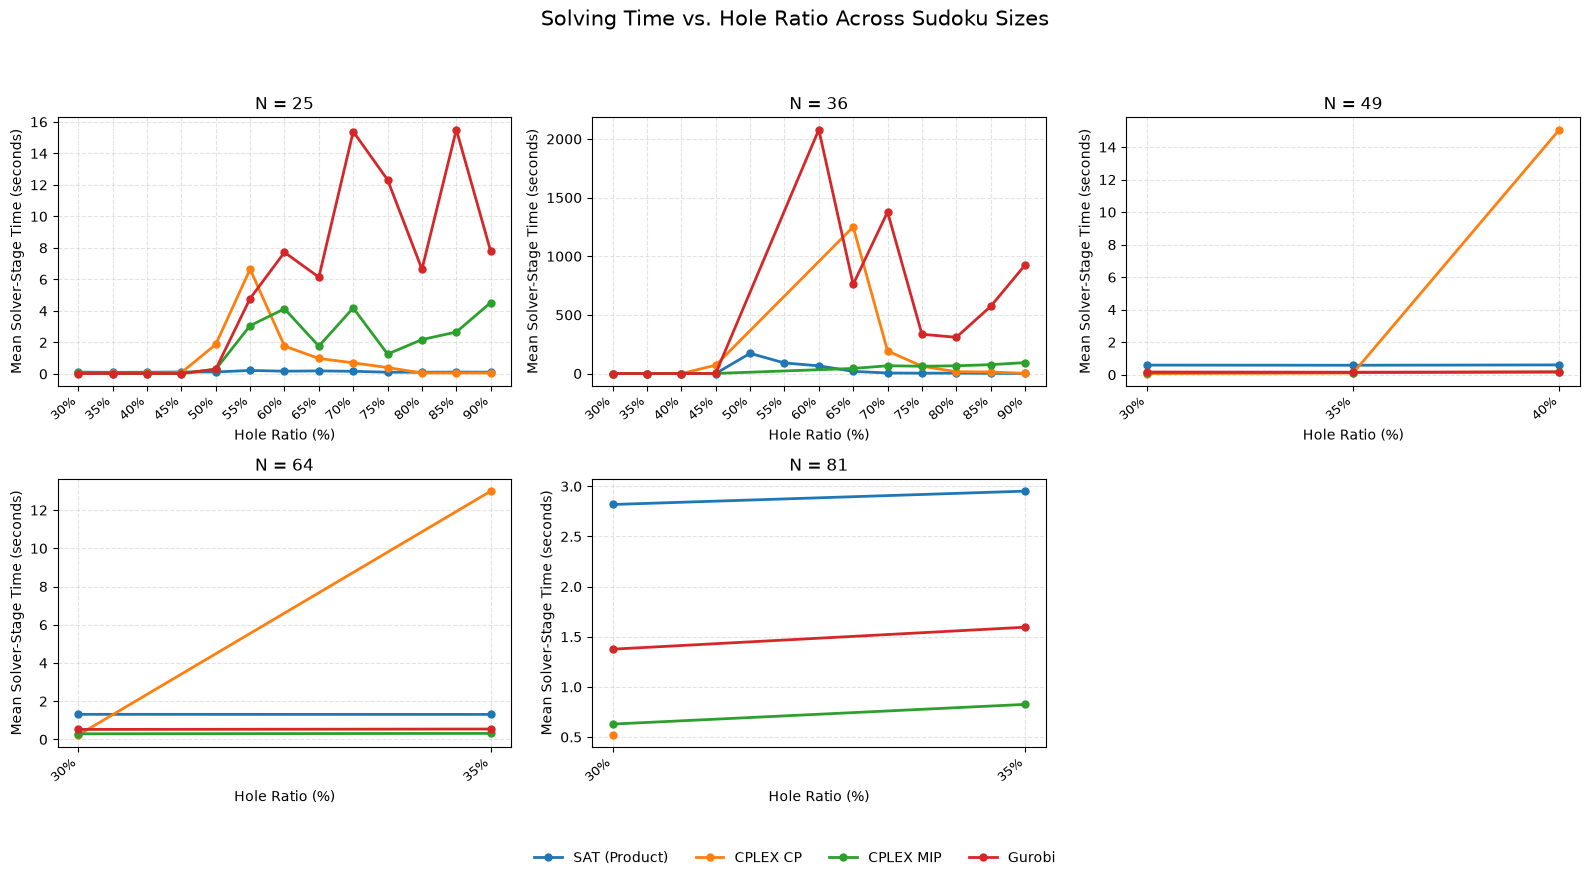

Mean solver-stage time (seconds):
method_label     CPLEX CP  CPLEX MIP     Gurobi  SAT (Product)
N  holes_ratio                                                
25 0.30            0.0463     0.0445     0.0254         0.1150
   0.35            0.0421     0.0241     0.0265         0.1009
   0.40            0.0442     0.0244     0.0268         0.1084
   0.45            0.0830     0.0231     0.0256         0.1262
   0.50            1.8692     0.2960     0.2991         0.1240
   0.55            6.6506     3.0633     4.7879         0.2208
   0.60            1.7700     4.1354     7.7210         0.1733
   0.65            0.9817     1.7621     6.1408         0.1917
   0.70            0.7051     4.1885    15.3858         0.1668
   0.75            0.4031     1.2594    12.3221         0.1095
   0.80            0.0625     2.1803     6.6429         0.1088
   0.85            0.0613     2.6595    15.5067         0.1167
   0.90            0.0619     4.5294     7.7818         0.1115
36 0.30            0.

In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

INPUT_FILE = "results\seed_sweep.csv"

IMAGE_DIR = Path(r"C:\kì I 2026-2027\Các vấn đề hiện đại của KHMT\sudoku-sat-encodings\benchmarks\results")
IMAGE_DIR.mkdir(parents=True, exist_ok=True)
CSV_DIR = Path(INPUT_FILE).resolve().parent

OUTPUT_FIGURE = (
    IMAGE_DIR / "solving_time_product_vs_cp_ilp_by_hole_ratio.png"
)
OUTPUT_CSV = (
    CSV_DIR / "solving_time_product_vs_cp_ilp_by_hole_ratio.csv"
)

GRID_SIZES = [25, 36, 49, 64, 81]

METHOD_LABELS = {
    "sat_product": "SAT (Product)",
    "cplex_cp": "CPLEX CP",
    "cplex_mip": "CPLEX MIP",
    "gurobi": "Gurobi",
}

METHOD_ORDER = [
    "sat_product",
    "cplex_cp",
    "cplex_mip",
    "gurobi",
]

SUCCESS_STATUSES = {
    "SOLVED", "SAT", "FEASIBLE", "OPTIMAL"
}

df = pd.read_csv(INPUT_FILE)

required_columns = {
    "N", "holes_ratio", "seed",
    "method", "status", "solve_time"
}

missing_columns = required_columns - set(df.columns)

if missing_columns:
    raise ValueError(
        f"CSV is missing required columns: {sorted(missing_columns)}"
    )

df["N"] = pd.to_numeric(df["N"], errors="coerce")
df["holes_ratio"] = pd.to_numeric(
    df["holes_ratio"], errors="coerce"
)
df["solve_time"] = pd.to_numeric(
    df["solve_time"], errors="coerce"
)

df["method"] = (
    df["method"].astype("string").str.strip().str.lower()
)

df["status"] = (
    df["status"]
    .astype("string")
    .str.strip()
    .str.upper()
    .str.replace(r"[\s-]+", "_", regex=True)
)

df["status"] = df["status"].replace({
    "TIME_OUT": "TIMEOUT",
})

valid_ratios = df["holes_ratio"].dropna()
if not valid_ratios.empty and valid_ratios.max() > 1:
    df["holes_ratio"] = df["holes_ratio"] / 100.0

data = df[
    df["N"].isin(GRID_SIZES)
    & df["method"].isin(METHOD_ORDER)
    & df["status"].isin(SUCCESS_STATUSES)
    & df["holes_ratio"].notna()
    & df["solve_time"].notna()
    & (df["solve_time"] >= 0)
].copy()

if data.empty:
    raise ValueError(
        "No successful observations found. "
        "Check the CSV status values and method names."
    )

summary = (
    data.groupby(
        ["N", "holes_ratio", "method"],
        as_index=False,
        observed=True
    )
    .agg(
        mean_solve_time=("solve_time", "mean"),
        std_solve_time=("solve_time", "std"),
        n_solved=("solve_time", "count"),
    )
)

summary["method_label"] = summary["method"].map(METHOD_LABELS)

summary.to_csv(OUTPUT_CSV, index=False)

fig, axes = plt.subplots(
    nrows=2,
    ncols=3,
    figsize=(16, 9)
)

axes = axes.flatten()

color_cycle = plt.rcParams["axes.prop_cycle"].by_key()["color"]

method_colors = {
    method: color_cycle[i % len(color_cycle)]
    for i, method in enumerate(METHOD_ORDER)
}

legend_handles = {}

for idx, N in enumerate(GRID_SIZES):
    ax = axes[idx]
    subset_N = summary[summary["N"] == N]

    for method in METHOD_ORDER:
        method_data = (
            subset_N[subset_N["method"] == method]
            .sort_values("holes_ratio")
        )

        if method_data.empty:
            continue

        line, = ax.plot(
            method_data["holes_ratio"] * 100,
            method_data["mean_solve_time"],
            marker="o",
            markersize=5,
            linewidth=2,
            linestyle="-",
            color=method_colors[method],
            label=METHOD_LABELS[method],
        )

        legend_handles[METHOD_LABELS[method]] = line

    ax.set_title(f"N = {N}", fontsize=12)
    ax.set_xlabel("Hole Ratio (%)", fontsize=10)
    ax.set_ylabel("Mean Solver-Stage Time (seconds)", fontsize=10)

    observed_ratios = sorted(
        subset_N["holes_ratio"].dropna().unique()
    )

    ax.set_xticks(np.array(observed_ratios) * 100)
    ax.set_xticklabels(
        [f"{ratio * 100:g}%" for ratio in observed_ratios],
        rotation=40,
        ha="right",
        fontsize=9
    )

    ax.grid(True, linestyle="--", alpha=0.35)

    if subset_N.empty:
        ax.text(
            0.5, 0.5,
            "No data",
            ha="center",
            va="center",
            transform=ax.transAxes
        )

axes[5].axis("off")

fig.legend(
    legend_handles.values(),
    legend_handles.keys(),
    loc="lower center",
    ncol=4,
    frameon=False,
    bbox_to_anchor=(0.5, 0.015),
    fontsize=10
)

fig.suptitle(
    "Solving Time vs. Hole Ratio Across Sudoku Sizes",
    fontsize=15,
    y=0.98
)

fig.tight_layout(rect=[0, 0.08, 1, 0.94])

fig.savefig(
    OUTPUT_FIGURE,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

print("Mean solver-stage time (seconds):")

print(
    summary.pivot_table(
        index=["N", "holes_ratio"],
        columns="method_label",
        values="mean_solve_time"
    ).round(4).to_string()
)

print("\nNumber of successful runs used for each mean:")

print(
    summary.pivot_table(
        index=["N", "holes_ratio"],
        columns="method_label",
        values="n_solved",
        aggfunc="sum"
    ).to_string()
)

print(f"\nFigure saved to: {OUTPUT_FIGURE}")
print(f"Summary CSV saved to: {OUTPUT_CSV}")
